# Show Sequences

Visualise the sequences from RAW files (IDEA export files).

Sequence files can be very large, but compress very efficiently. They are stored as .gz files and read using gzip.

In [131]:
import gzip

# better to use numpy directly

def read_sequence(filepath, max_ncommentlines=20):
    import numpy as np
    import re

    header = dict.fromkeys(['dt', 't0', 'tF'])
    with gzip.open(filepath, 'rt') as file:  # open .gz file directly in memory
        for num, line in enumerate(file, 1):
            if num > max_ncommentlines:
                break
            elif line.startswith(';'):  # comment
                line = re.sub(' +', ' ', line)  # sanitise: multiple spaces into single
                timestep = re.match('^; Time Step = (\d+) SRT', line)
                if timestep:
                    header['dt'] = float(timestep.group(1))
                starttime = re.match('^; Start Time = (\d+) SRT', line)
                if starttime:
                    header['t0'] = float(starttime.group(1))
                endtime = re.match('^; End Time = (\d+) SRT', line)
                if endtime:
                    header['tF'] = float(endtime.group(1))
                names = re.search('(\t)', line)
                if names:  # line contains \t, so is names row
                    names = re.split('\t', line)
                    for col, name in enumerate(names, 0):
                        labels = ['X Gradient', 'Y Gradient', 'RF-Signal', 'Z Gradient', 'ADC Signal Data']
                        if 'X Gradient' in name:
                            names[col] = 'X Gradient'
                        if 'Y Gradient' in name:
                            names[col] = 'Y Gradient'
                        if 'Z Gradient' in name:
                            names[col] = 'Z Gradient'
                        if 'ADC Signal Data' in name:
                            names[col] = 'ADC Signal Data'
                        if 'RF-Signal' in name:
                            names[col] = 'RF-Signal'
                    names = names[0:-1]  # last one is just \n
        labels = names

    dt = header['dt']*0.1*1e-6  # from SRT to s #TODO: why 0.1?
    t0 = header['t0']*dt
    tF = header['tF']*dt

    # supports gz compression of file
    # delimiter of None (default) means whitespace (space and/or tab)
    content = np.genfromtxt(filepath, delimiter=None, comments=';', autostrip=True, dtype='f')  # names=labels
    # re-organise s.t. first axis is different data types
    content = content.T  #TODO: option to genfromtxt??

    # convert mT/m to T/m
    #TODO: for this, need to enable names
    #content['X_Gradient'] *= 1e3
    #content['Y_Gradient'] *= 1e3
    #content['Z_Gradient'] *= 1e3

    return content, labels

In [129]:
from matplotlib import pyplot as plt
def plot_seq(seqdata, labels):
    fig, axes = plt.subplots(5, 1, sharex=True)
    for axis, ylab, data in zip(axes, labels, seqdata):
        axis.set_ylabel(ylab)
        axis.plot(data)

## bvalue calc

In [125]:
import math

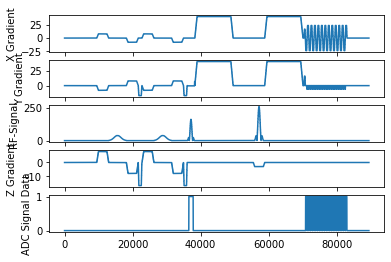

In [132]:
# Choose a file
pgse_Gxy_dat, pgse_Gxy_leg = read_sequence('data/general_40mTm/small/PGSE.txt.gz')
pgse_Gxy_dat
plot_seq(pgse_Gxy_dat, labels=pgse_Gxy_leg)

In [ ]:
# split the RF pulses
def split_pulses(RFdata, nRFpulses, showplots=False):

    # find peaks in RF data and determine which are the relevant pulses.
    RFpulsethresh = 100  # This may need redefining - must be > fat sat pulse and < every STEAM pulse
    minpeakseparation = 100  # Minimum distance between RF pulses. *units of 10us.  - i.e. 1ms? 
    RFpeakamp, RFpeakloc = findpeaks(RFdata, 'MINPEAKHEIGHT', RFpulsethresh, 'MINPEAKDISTANCE', minpeakseparation)

    # RFpeakloc is [peak1_0, peak2_0, peak3_0, peak1_1, peak2_1, peak3_1, ..., peak1_N, peak2_N, peak3_N]
    for ind in range(nRFpulses):
        pulse_locations[ind] = RFpeakloc[ind:-1:nRFpulses]

    if showplots:
        plt.figure()
        plt.plot(RFdata)
        plt.plot(RFpeakloc, RFpeakamp, 'ro')  # ro vs gx
        colors = ['r', 'g', 'b']
        for i in range(nRFpulses):
            vline(pulse_locations[i], color=colors[i])

nRFpulses = 2
pulse_locations = split_pulses(RFdata, nRFpulses)

In [ ]:
# Find start of each readout

ADCdiff = diff(ADCdata)
ADCstartpoints = find(ADCdiff>0)

i = 1
while i < numel(pulse_locations{end}):
    greaterADCs = find(ADCstartpoints>pulse_locations{end}[i], 1)
    firstADCstart = ADCstartpoints[greaterADCs]
    if firstADCstart > pulse_locations[0](ind+1):
        # Attempt to remove RF pulses without corresponding ADCs
        for ii = 1:numel(pulse_locations):
            pulse_locations[ii][i] = []
    else:
        readoutstartpoints[i] = firstADCstart
        i += 1

# Assume the last line isn't a dummy cycle
ind = numel(pulse_locations{end})
greaterADCs = find(ADCstartpoints>pulse_locations{end}(ind))
firstADCstart = ADCstartpoints(greaterADCs(1))
readoutstartpoints(ind) = firstADCstart

In [ ]:
bmatrix = zeros(numel(pulse_locations{end}), 3,3)
for i = 1:numel(pulse_locations{end})  # Loop over images

    ### Preallocate data
    G_i = zeros(readoutstartpoints[i] - pulse_locations{1}[i] + 1, 3)

    ### First part of the STEAM
    for indt = (pulse_locations{1}[i] + 1):pulse_locations{2}[i]
        cindt = indt - pulse_locations{1}[i] + 1
        G_i(cindt, :) = G{ind}(cindt-1, :)+gradients(indt, :)*timestep  # Integrate gradient waveforms

    ### Between the second and third RF pulses the integral is constant and equal to the value at second RF pulse
    # I think we could do better than this.  If we have an ETL>1 this is poor.
    if nRFpulses == 2:  # SE
        mixingrange = (pulse_locations{2}[i]-pulse_locations{1}[i]+2,
                       pulse_locations{2}[i]-pulse_locations{1}[i]+2)
        restartpoint = pulse_locations{2}[i]+1
    elif nRFpulses == 3:  # STEAM
        mixingrange = (pulse_locations{2}[i]-pulse_locations{1}[i]+2,
                       pulse_locations{3}[i]-pulse_locations{1}[i]+1)
        restartpoint = pulse_locations{3}[i]
    G_i(mixingrange[0]:mixingrange[1], :) = repmat(G[i]((mixingrange[0]-1),:), [mixingrange[1]-mixingrange[0]+1 1])

    ### Second part of STEAM where 90+90 -> invert gradients
    for indt = restartpoint:readoutstartpoints(ind):
        cindt = indt-pulse_locations{1}(ind)+1
        G_i(cindt, :) = G_i(cindt-1, :) - gradients(indt, :)*timestep

    ### Then do outer integral to get the b matrix
    Gsq_ii = zeros(3,3)
    for indt = 2:size(G_i, 1):
        Gsq_ii = (transpose(G_i(indt, :))*G_i(indt, :))  # Square intergral of gradient

    gamma = 42.6e6*2*math.pi
    bmatrix(i, :,:) = Gsq_ii*timestep*gamma**2

In [ ]:
# Save results in a text file with the same file name as the input file BUT append '_simresults'
fprintf(fidout, 'xx\txy\txz\tyx\tyy\tyz\tzx\tzy\tzz\ttrace\n');
for ind = 1:numel(pulse_locations{end})
    fprintf(fidout, '%e\t%e\t%e\t%e\t%e\t%e\t%e\t%e\t%e\t%e\n',
            bmatrix(ind, 1,1),
            bmatrix(ind, 1,2),
            bmatrix(ind, 1,3),
            bmatrix(ind, 2,1),
            bmatrix(ind, 2,2),
            bmatrix(ind, 2,3),
            bmatrix(ind, 3,1),
            bmatrix(ind, 3,2),
            bmatrix(ind, 3,3),
            trace(squeeze(bmatrix(ind, :,:)))
           )

## Prisma sequences

data/prisma_80mTm/noheader/Monopolar_Prisma.txt.gz
```
Monopolar

; Diagram data of sequence 'SimulationProtocol' [C:/Users/idea/AppData/Local/Temp/SequenceSimulation/2018_06_27_01_26_11/]
; Time Settings:
; Start Time = 0  SRT
; End Time = 43277400  SRT
; Time Step = 10 SRT
;              ADC Signal Data	           X Gradient (GPA 0)	           Y Gradient (GPA 0)	           Z Gradient (GPA 0)	RF-Signal (ch. 0, 1H, 123.2 MHz)	
```

data/prisma_80mTm/noheader/M2-SE_Prisma.txt.gz
```
M2-SE

; Diagram data of sequence 'SimulationProtocol' [C:/Users/idea/AppData/Local/Temp/SequenceSimulation/2018_06_27_01_33_47/]
; Time Settings:
; Start Time = 0  SRT
; End Time = 43309800  SRT
; Time Step = 10 SRT
;              ADC Signal Data	           X Gradient (GPA 0)	           Y Gradient (GPA 0)	           Z Gradient (GPA 0)	
```

# TIMINGS

### MCSE timings

key timing points:
- t1 = 0.002605333333333
- t2 = 0.008035333333333
- t3 = 0.010702000000000
- t4 = 0.018699142446879

difference between these are the following durations:
- del_1 = 0.00543000000000
- 2*tau = 0.00266666666667
- del_2 = 0.00799714244688

### STEAM timings

* dt = 1e-6
* t0 = 66425  # very first point

* t1 = 67999  # last point where G=0 before ramp goes up
* t2 = 68660  # first point on G=Gmax after ramp went up
* t3 = 69559  # last point on G=Gmax before ramp goes down
* t4 = 70220  # first point where G=0 after ramp went down

* t5 = 1067999  # see iT_1
* t6 = 1068660  # see iT_2
* t7 = 1069559  # see iT_3
* t8 = 1070220  # see iT_4

* t9 = 1070969  # very last point

* epsilon = (t2-t1)*dt
* delta   = (t3-t2)*dt + epsilon
* DELTA   = (t5-t1)*dt  # should be 1s
